In [1]:
from preprocessing import load_GSE127465, load_nsclc_cosmx
# from transcript_sampling import add_top_st_matches_with_coords
from mapping import integrate_single_st_file_with_harmony
import anndata as ad
import numpy as np
import pandas as pd
from label_transfer import preprocess_and_transfer_cell_types, make_label_correspondence_table, plot_label_correspondence_heatmap
import matplotlib.pyplot as plt
import os

spatial_dir = '/compute/oven-0-13/jwinchel/spatial_adata/'

# sc_data = load_GSE127465('/compute/oven-0-13/jwinchel/scRNA-seq',)
sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/scRNA-seq/adata/GSE127465_tumor_integrated.h5ad')
# sc_data = sc_data[sc_data.obs['Tissue']=='tumor'] # only tumor data

/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:

In [2]:
sc_data.obs[['sample','cell_ID']].drop_duplicates().shape

(40362, 2)

In [3]:
# cell_types = sorted(sc_data.obs['cell_type'].unique())
# cell_type_dict = {cell_types[i]: -(i+1) for i in range(len(cell_types))}

# sc_data.uns['cell_type_dict'] = cell_type_dict

# sc_data.obs['split'] = 'train'
# sc_data.obs.loc[sc_data.obs['Patient']=='p2','split'] = 'val'
# sc_data.write_h5ad('/compute/oven-0-13/jwinchel/scRNA-seq/adata/GSE127465_tumor_integrated.h5ad')

In [3]:

st_data = ad.read_h5ad(os.path.join(spatial_dir,'cosmx_nsclc_Lung9-Rep1_adata_annotated.h5ad'))
# st_data.obsm['X_pca_harmony'] = st_data.obsm['X_pca_harmony_Lung_Rep1']

In [4]:
st_data = st_data[st_data.obs['cell_type']!='nan']

In [ ]:
# Run preprocessing / label transfer
sc_data = preprocess_and_transfer_cell_types(
    sc_data,
    st_data,
    source_major_type_col="Major cell type",
    initial_target_col="cell_type",
    sc_tcell_selector_col="cell_type",
    sc_tcell_selector_value="T cells",
    st_tcell_selector_col="cell_type",
    st_tcell_selector_prefix="T",
    st_merged_label_col="cell_type",
    embedding_key="X_pca_harmony_Lung9_Rep1",
    n_neighbors=30,
    sketch_size=30000,
    random_state=0,
)

# sc_data.write_h5ad('/compute/oven-0-13/jwinchel/scRNA-seq/adata/GSE127465_tumor_integrated.h5ad')
# Build and plot correspondence heatmap
ct = make_label_correspondence_table(
    sc_data,
    predicted_col="cell_type",
    original_col="Major cell type",
)

fig, ax = plot_label_correspondence_heatmap(ct)
# fig.savefig('/home/jwinchel/Syndri/plots/label_mapping.png')

KeyError: 'X_pca_harmony_Lung9_Rep1'

In [4]:
import os
spatial_files = sorted([f for f in os.listdir(spatial_dir) if f.endswith('annotated.h5ad')])

for f in spatial_files:
    tissue_name = f.split('_')[2].replace('-','_')

    print(tissue_name)

    if f'X_pca_harmony' in sc_data.obsm:
        continue
    # batch integration
    sc_data, st_data, cov =  integrate_single_st_file_with_harmony(st_file=os.path.join(spatial_dir, f), sc_data_orig=sc_data,tissue_name=tissue_name)

    # st_data.write_h5ad(os.path.join(spatial_dir, f))
    
    print(sc_data.obsm)



Lung12
Lung13
Lung5_Rep1
Lung5_Rep2
Lung5_Rep3
Lung6
Lung9_Rep1
Lung9_Rep2


In [ ]:
st_meta = pd.read_csv('/compute/oven-0-13/jwinchel/NSCLC_ST_cell_metadata.csv')

In [ ]:
# st_meta.loc[(st_meta['Slide_name']=='Lung9')&(st_meta['slide_ID_numeric']==5),'Slide_name'] = 'Lung9_Rep1'
# st_meta.loc[(st_meta['Slide_name']=='Lung9')&(st_meta['slide_ID_numeric']==6),'Slide_name'] = 'Lung9_Rep2'

In [ ]:
slide_id = st_meta[['Run_Tissue_name','slide_ID_numeric']].drop_duplicates().values
slide_id = dict(zip(slide_id[:,0], slide_id[:,1]))
slide_id

In [ ]:
integrated_adatas = []
for pca_key in sc_data.obsm.keys():
    if not pca_key.startswith('X_pca_harmony'):
        continue
    
    tissue_adata = sc_data.copy()
    tissue_name = "_".join(pca_key.split('_')[3:])
    tissue_adata.obsm['X_pca_harmony'] = tissue_adata.obsm[pca_key]
    for key in sc_data.obsm.keys():
        del tissue_adata.obsm[key]
    tissue_adata.obs['harmony_spatial_tissue'] = tissue_name
    tissue_adata.obs['harmony_spatial_id'] = tissue_adata.obs['harmony_spatial_tissue'].map(slide_id)
    print(tissue_adata.obs['harmony_spatial_id'].value_counts())
    integrated_adatas.append(tissue_adata)
    # break
    # integrated_adatas.append(sc_data.obsm[pca_key])

integrated_adata = ad.concat(integrated_adatas, axis=0)



In [ ]:
integrated_adata.obs['harmony_spatial_tissue'].value_counts()

In [76]:
drop_cols = [c for c in sc_data.obs.columns if c.startswith(('st_match','sampled_st'))]
sc_data.obs = sc_data.obs.drop(columns=drop_cols)

In [2]:
sc_data.obs['harmony_spatial_tissue'].value_counts()

harmony_spatial_tissue
Lung5_Rep1    40362
Lung5_Rep2    40362
Lung5_Rep3    40362
Lung6         40362
Lung9_Rep1    40362
Lung9_Rep2    40362
Lung12        40362
Lung13        40362
Name: count, dtype: int64

In [3]:
sc_data.obs['sampled_st_id'].dtype

CategoricalDtype(categories=['12', '18', '37', '39', '40', '45', '47', '49', '53', '56',
                  ...
                  '800541', '800542', '800545', '800547', '800553', '800554',
                  '800555', '800556', '800557', '800558'],
, ordered=False, categories_dtype=object)

In [7]:
from mapping import map_sc_subset_to_st
import importlib
import mapping
importlib.reload(mapping)
spatial_files = sorted([f for f in os.listdir(spatial_dir) if f.endswith('annotated.h5ad')])
spatial_files
for f in spatial_files:
    tissue_name = f.split('_')[2].replace('-','_')
    print(tissue_name)
    st_data = ad.read_h5ad(os.path.join(spatial_dir, f))
    print(st_data.obs.shape,sc_data.obs.shape)
    
    st_data.obsm['X_pca_harmony'] = st_data.obsm['X_pca_harmony_'+tissue_name]
    del st_data.obsm['X_pca_harmony_'+tissue_name]
    sc_data, coverage, match_result = map_sc_subset_to_st(
        sc_data=sc_data,
        st_data=st_data,
        tissue_name=tissue_name,
        embedding_key="X_pca_harmony",
        tissue_col="harmony_spatial_tissue",
        capped_sampling_on_exhausted='raise',
        max_reuse_per_st=20,
        n_matches=100
    )

Lung12
(74025, 43) (322896, 52)


/home/jwinchel/Syndri/code/mapping.py:366: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  new_data.obs[col] = np.nan
/home/jwinchel/Syndri/code/mapping.py:366: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  new_data.obs[col] = np.nan
/home/jwinchel/Syndri/code/mapping.py:366: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newfram

Lung13
(82863, 43) (322896, 440)
Lung5_Rep1
(98002, 44) (322896, 440)
Lung5_Rep2
(106689, 43) (322896, 440)
Lung5_Rep3
(100294, 43) (322896, 440)
Lung6
(93825, 43) (322896, 440)
Lung9_Rep1
(91992, 43) (322896, 440)
Lung9_Rep2
(150549, 43) (322896, 440)


In [8]:
sc_data.obs

,species,filename,sample,GSM_ID,cell_ID,Patient,Tissue,Barcoding emulsion,Library,Barcode,...,st_match_98_x,st_match_98_y,st_match_99_id,st_match_99_dist,st_match_99_x,st_match_99_y,st_match_100_id,st_match_100_dist,st_match_100_x,st_match_100_y
cell_ID_long,,,,,,,,,,,,,,,,,,,,,
p1t1-bcIIOD-7,human,GSM3635278_human_p1t1_raw_counts,p1t1,GSM3635278,bcIIOD,p1,tumor,p1t,p1t1,bcIIOD,...,8222.666667,-153474.333333,26937,8.827546,838.444444,-152479.333333,65908,8.839399,2017.444444,-136715.333333
p1t1-bcHTNA-7,human,GSM3635278_human_p1t1_raw_counts,p1t1,GSM3635278,bcHTNA,p1,tumor,p1t,p1t1,bcHTNA,...,16815.888889,-157491.333333,50153,6.365000,14846.888889,-144484.333333,31388,6.367845,12701.888889,-150674.333333
p1t1-bcDLAV-7,human,GSM3635278_human_p1t1_raw_counts,p1t1,GSM3635278,bcDLAV,p1,tumor,p1t,p1t1,bcDLAV,...,-3482.777778,-137262.333333,36030,8.871420,-2519.777778,-148221.333333,3558,8.878857,2181.444444,-157190.333333
p1t1-bcHNVA-7,human,GSM3635278_human_p1t1_raw_counts,p1t1,GSM3635278,bcHNVA,p1,tumor,p1t,p1t1,bcHNVA,...,-3848.777778,-137684.333333,60971,6.028487,14304.888889,-140945.333333,31288,6.031329,12763.888889,-150468.333333
p1t1-bcALZN-7,human,GSM3635278_human_p1t1_raw_counts,p1t1,GSM3635278,bcALZN,p1,tumor,p1t,p1t1,bcALZN,...,-2814.777778,-155956.333333,70638,7.930860,8204.666667,-137638.333333,65234,7.934494,2346.444444,-135491.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
p7t2-bcFAUI-6,human,GSM3635302_human_p7t2_raw_counts,p7t2,GSM3635302,bcFAUI,p7,tumor,p7t,p7t2,bcFAUI,...,3578.888889,992.222222,780003,6.793837,4330.888889,286.222222,789542,6.795261,-12050.777778,2253.222222
p7t2-bcFHTY-6,human,GSM3635302_human_p7t2_raw_counts,p7t2,GSM3635302,bcFHTY,p7,tumor,p7t,p7t2,bcFHTY,...,-16549.000000,-4613.777778,711389,7.827358,1861.666667,-15575.777778,687807,7.831401,-14755.000000,-18960.777778
p7t2-bcBHQQ-6,human,GSM3635302_human_p7t2_raw_counts,p7t2,GSM3635302,bcBHQQ,p7,tumor,p7t,p7t2,bcBHQQ,...,-15720.000000,3869.222222,685752,6.071482,-14871.000000,-19078.777778,748333,6.073016,-15737.000000,-6258.777778


In [9]:
counts = sc_data.obs.groupby(['sampled_st_id','harmony_spatial_tissue'])['sampled_st_id'].count()
np.percentile(counts[counts!=0],99.99)

/tmp/ipykernel_1227687/3601872259.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sc_data.obs.groupby(['sampled_st_id','harmony_spatial_tissue'])['sampled_st_id'].count()


20.0

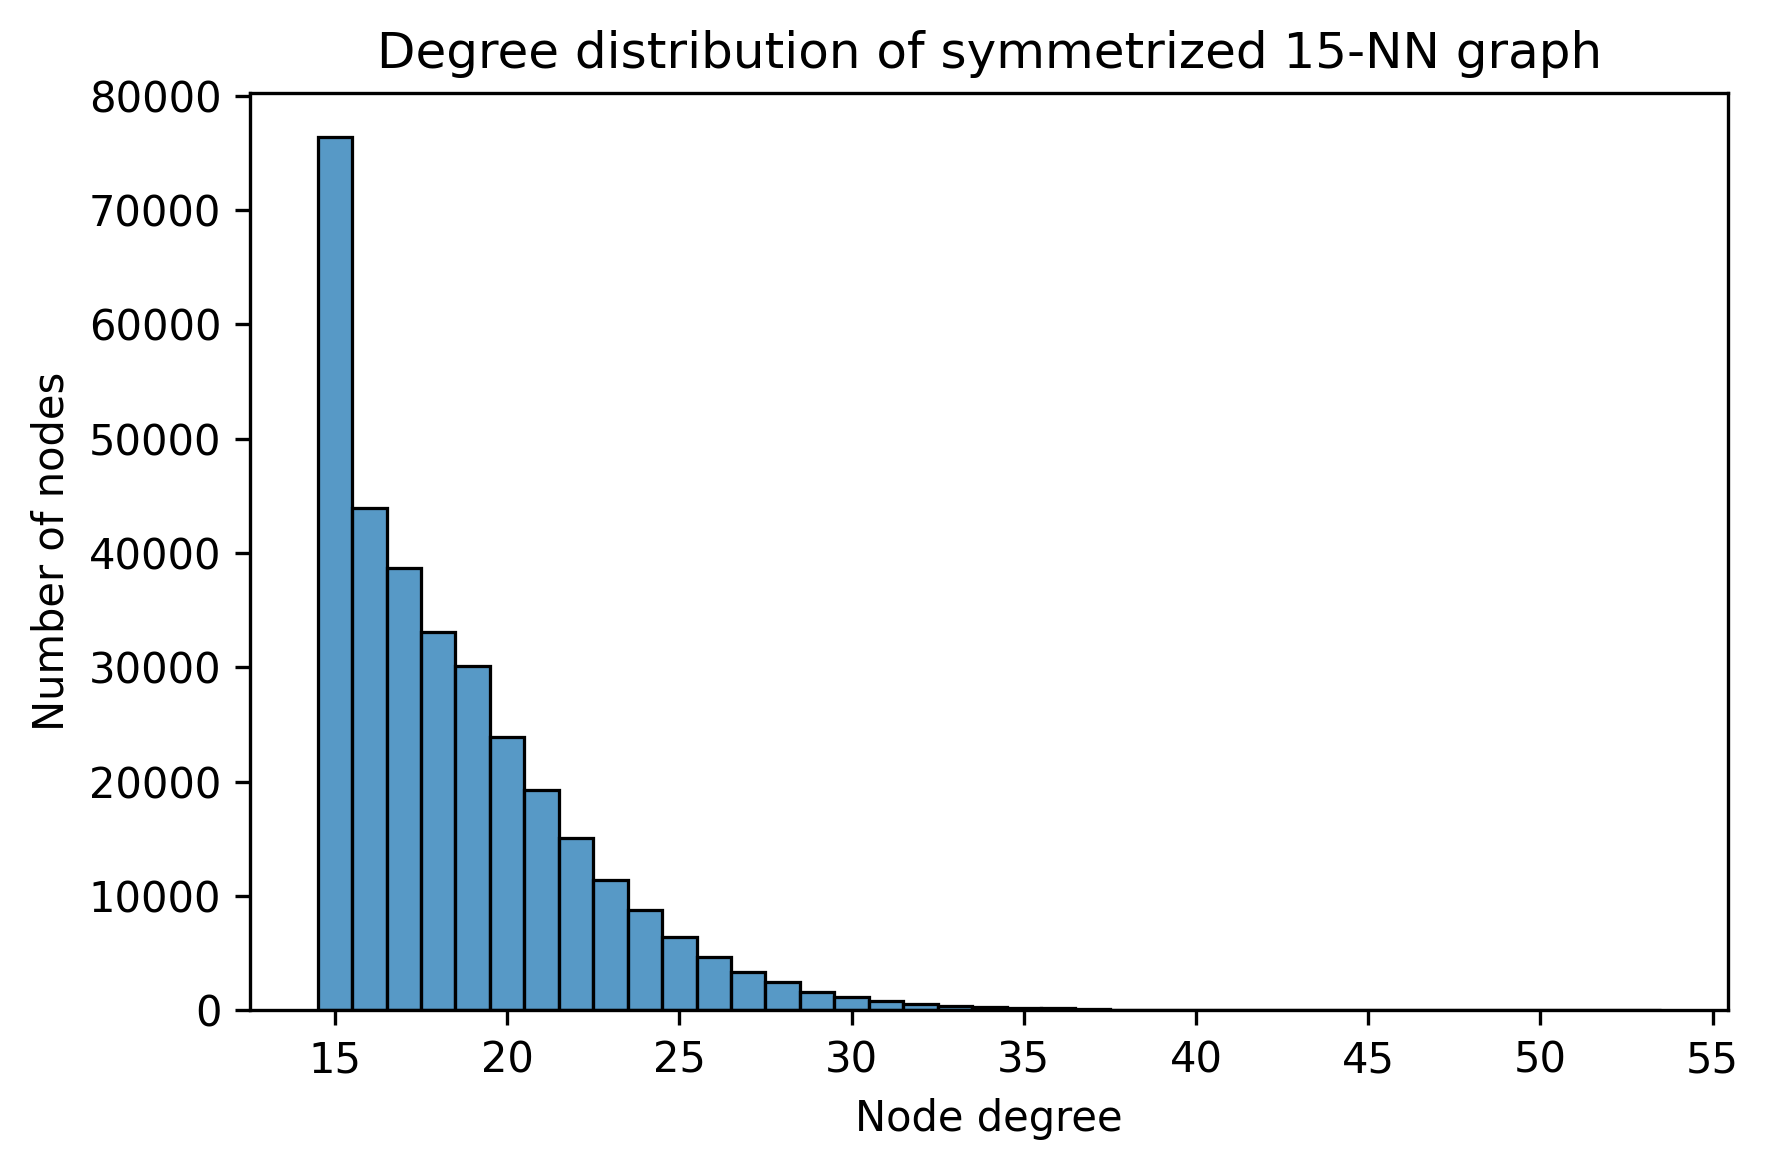

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import kneighbors_graph
degrees = []
tissues = sorted(sc_data.obs['harmony_spatial_tissue'].unique())

for t in tissues:
    # X should be shape: n_samples x n_features
    # Example:
    # X = adata.obsm["X_pca"]
    # X = coords
    # X = expression_matrix

    k = 15
    X = sc_data[sc_data.obs['harmony_spatial_tissue']==t].obs[['sampled_st_x','sampled_st_y']].dropna().values

    # Directed KNN graph: each node points to exactly k neighbors
    A_directed = kneighbors_graph(
        X,
        n_neighbors=k,
        mode="connectivity",
        include_self=False,
    )

    # Symmetrize to make an undirected graph
    # Edge exists if i is a neighbor of j OR j is a neighbor of i
    A = A_directed.maximum(A_directed.T)

    # Node degree = number of edges per node
    degrees.append(np.asarray(A.sum(axis=1)).ravel())

degrees= np.concatenate(degrees)
# degrees=degrees[degrees>50]
plt.figure(figsize=(6, 4),dpi=300)
sns.histplot(x=degrees, bins=np.arange(degrees.min(), degrees.max() + 2) - 0.5)
plt.xlabel("Node degree")
plt.ylabel("Number of nodes")
plt.title(f"Degree distribution of symmetrized {k}-NN graph")
plt.tight_layout()
plt.show()

In [ ]:
# sc_data.write_h5ad(os.path.join('/compute/oven-0-13/jwinchel/scRNA-seq/adata/','GSE127465_tumor_integrated_hardcap.h5ad'))

In [31]:
integrated_adata.obs['cell_ID_long'] = integrated_adata.obs['sample'].astype(str) + '-' + integrated_adata.obs['cell_ID'].astype(str) + '-' + integrated_adata.obs['harmony_spatial_id'].astype(str)

In [32]:
integrated_adata.obs.set_index('cell_ID_long', inplace=True)

In [ ]:
integrated_adata.obs.columns

In [ ]:
integrated_adata.obs

In [ ]:
import sys
integrated_adata.write_h5ad(os.path.join('/compute/oven-0-13/jwinchel/scRNA-seq/adata/','GSE127465_tumor_integrated_hardcap.h5ad'))

In [34]:
integrated_adata.obs['harmony_spatial_tissue'].unique()

['Lung12', 'Lung13', 'Lung5_Rep1', 'Lung5_Rep2', 'Lung5_Rep3', 'Lung6', 'Lung9_Rep1', 'Lung9_Rep2']
Categories (8, object): ['Lung5_Rep1', 'Lung5_Rep2', 'Lung5_Rep3', 'Lung6', 'Lung9_Rep1', 'Lung9_Rep2', 'Lung12', 'Lung13']